In [1]:
# ===== CELL 1: Import Libraries =====
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import KFold, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import mean_squared_error
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor

from catboost import CatBoostRegressor

print("✅ All libraries imported successfully")

✅ All libraries imported successfully


In [2]:
# ===== CELL 2: Load Data =====
print("\n📊 LOADING DATA...")
DATA_DIR = "/kaggle/input/playground-series-s6e1"

train = pd.read_csv(f"{DATA_DIR}/train.csv")
test = pd.read_csv(f"{DATA_DIR}/test.csv")

print(f"Training set shape: {train.shape}")
print(f"Test set shape: {test.shape}")

# Separate features and target
X = train.drop(columns=["exam_score", "id"])
y = train["exam_score"]
X_test = test.drop(columns=["id"])

print(f"\n✅ Data loaded successfully")
print(f"Features: {X.shape[1]}")
print(f"Training samples: {len(X)}")
print(f"Test samples: {len(X_test)}")


📊 LOADING DATA...
Training set shape: (630000, 13)
Test set shape: (270000, 12)

✅ Data loaded successfully
Features: 11
Training samples: 630000
Test samples: 270000


Exploratory Data Analysis (EDA)

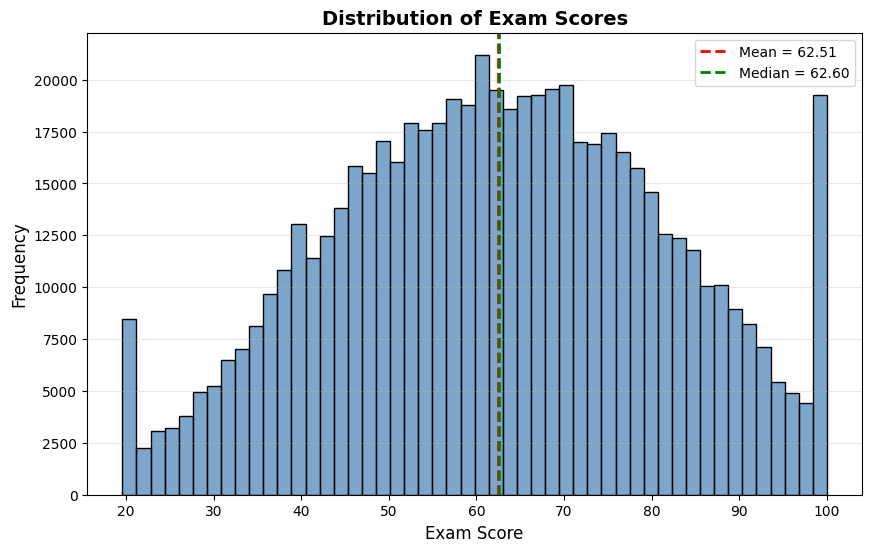

Score Statistics:
Mean: 62.51
Std: 18.92
Min: 19.60
Max: 100.00


In [3]:
# ===== CELL 3: Exploratory Data Analysis - Distribution =====
plt.figure(figsize=(10, 6))
sns.histplot(y, bins=50, edgecolor='black', alpha=0.7, color='steelblue')
plt.axvline(y.mean(), color='red', linestyle='--', linewidth=2, label=f'Mean = {y.mean():.2f}')
plt.axvline(y.median(), color='green', linestyle='--', linewidth=2, label=f'Median = {y.median():.2f}')
plt.xlabel('Exam Score', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.title('Distribution of Exam Scores', fontsize=14, fontweight='bold')
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.show()

print(f"Score Statistics:")
print(f"Mean: {y.mean():.2f}")
print(f"Std: {y.std():.2f}")
print(f"Min: {y.min():.2f}")
print(f"Max: {y.max():.2f}")

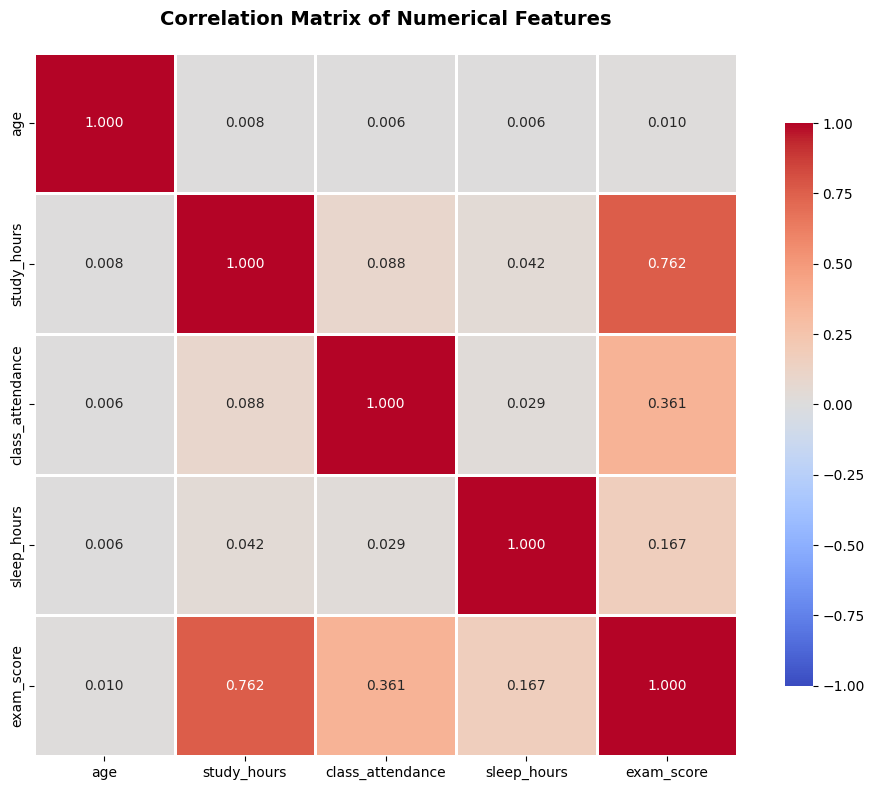


📊 Key Correlations with Exam Score:
exam_score          1.000000
study_hours         0.762267
class_attendance    0.360954
sleep_hours         0.167410
age                 0.010472
Name: exam_score, dtype: float64


In [4]:
# ===== CELL 4: Correlation Heatmap (CORRECTED - Numerical Features Only) =====
# CORRECT APPROACH: Only numerical features
numerical_features = ['age', 'study_hours', 'class_attendance', 'sleep_hours', 'exam_score']
correlation_matrix = train[numerical_features].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, 
            annot=True,           # Show correlation values
            fmt='.3f',            # 3 decimal places
            cmap='coolwarm',      # Color scheme
            square=True,          # Square cells
            linewidths=1,         # Grid lines
            cbar_kws={"shrink": 0.8},
            vmin=-1, vmax=1,      # Correlation range
            center=0)             # Center colormap at 0

plt.title('Correlation Matrix of Numerical Features', fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

print("\n📊 Key Correlations with Exam Score:")
print(correlation_matrix['exam_score'].sort_values(ascending=False))

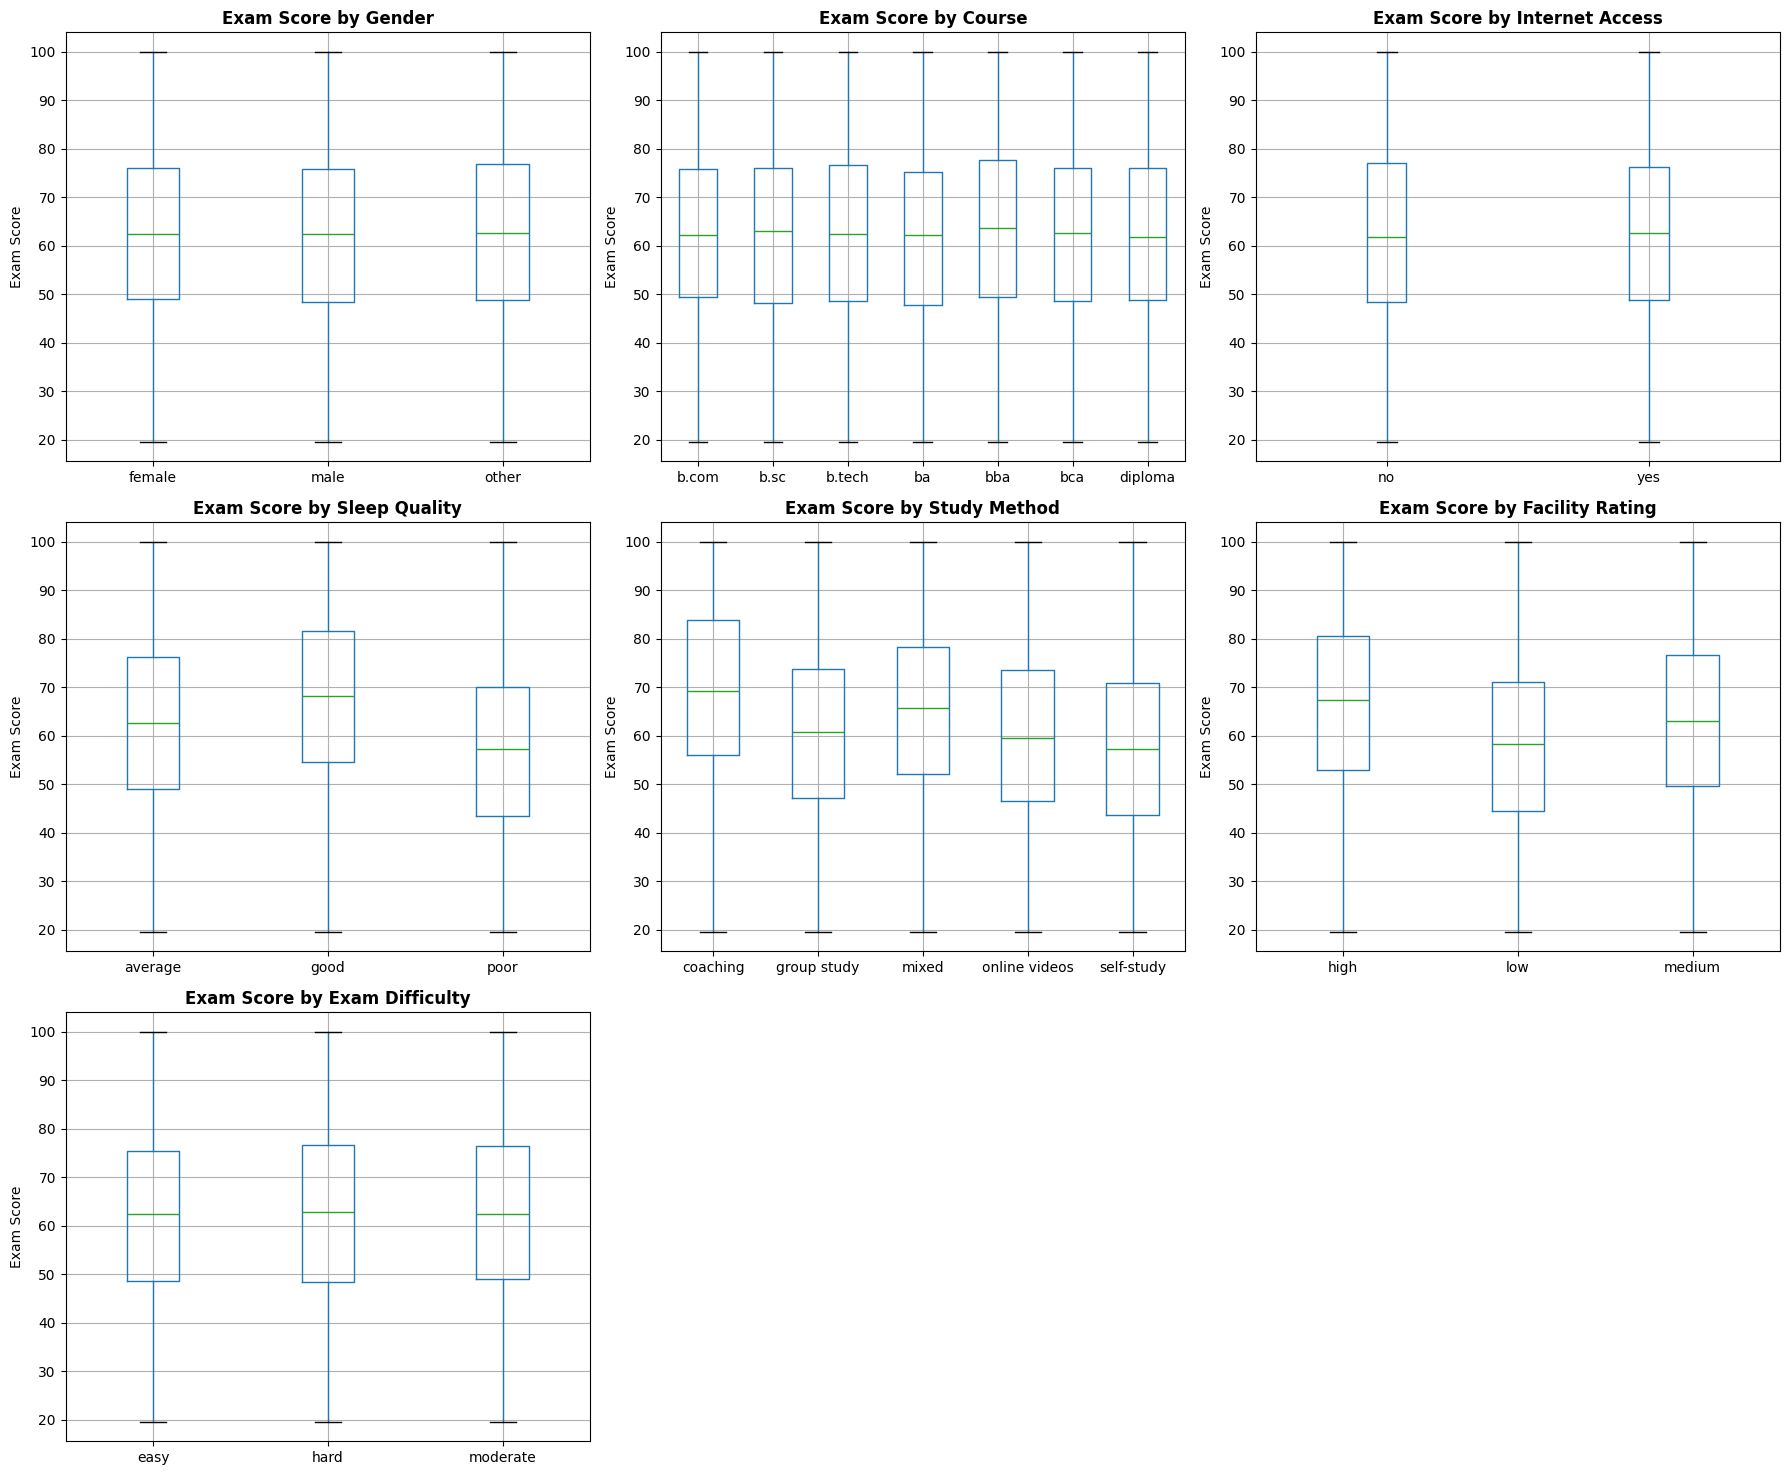

In [5]:
# ===== CELL 5: Categorical Features Analysis =====
categorical_features = ['gender', 'course', 'internet_access', 'sleep_quality', 
                        'study_method', 'facility_rating', 'exam_difficulty']

fig, axes = plt.subplots(3, 3, figsize=(18, 15))
axes = axes.ravel()

for idx, col in enumerate(categorical_features):
    train.boxplot(column='exam_score', by=col, ax=axes[idx])
    axes[idx].set_title(f'Exam Score by {col.replace("_", " ").title()}', fontsize=12, fontweight='bold')
    axes[idx].set_xlabel('')
    axes[idx].set_ylabel('Exam Score', fontsize=10)
    axes[idx].get_figure().suptitle('')  # Remove auto-title

# Hide extra subplots
for idx in range(len(categorical_features), len(axes)):
    axes[idx].set_visible(False)

plt.tight_layout()
plt.show()

In [6]:
# ===== CELL 6: Feature Engineering & Encoding =====
print("\n🔧 FEATURE ENGINEERING...")

# Identify categorical and numerical columns
categorical_cols = ['gender', 'course', 'internet_access', 'sleep_quality', 
                    'study_method', 'facility_rating', 'exam_difficulty']
numerical_cols = ['age', 'study_hours', 'class_attendance', 'sleep_hours']

# Create copies for different models
X_encoded = X.copy()
X_test_encoded = X_test.copy()

# Label Encoding for tree-based models (CatBoost, Random Forest, Decision Tree)
label_encoders = {}
for col in categorical_cols:
    le = LabelEncoder()
    # Fit on combined data to handle unseen categories
    combined = pd.concat([X[col], X_test[col]])
    le.fit(combined)
    
    X_encoded[col] = le.transform(X[col])
    X_test_encoded[col] = le.transform(X_test[col])
    label_encoders[col] = le

print(f"✅ Label encoding complete")
print(f"Encoded training shape: {X_encoded.shape}")


🔧 FEATURE ENGINEERING...
✅ Label encoding complete
Encoded training shape: (630000, 11)


In [7]:
# ===== CELL 7: Decision Tree Baseline =====
print("\n🌳 TRAINING DECISION TREE (Baseline)...")

dt = DecisionTreeRegressor(
    max_depth=10,
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=42
)

dt.fit(X_encoded, y)
dt_preds = dt.predict(X_test_encoded)

# Cross-validation
dt_cv_scores = cross_val_score(dt, X_encoded, y, 
                                cv=5, 
                                scoring='neg_root_mean_squared_error',
                                n_jobs=-1)
dt_rmse = -dt_cv_scores.mean()

print(f"Decision Tree CV RMSE: {dt_rmse:.4f} (±{dt_cv_scores.std():.4f})")


🌳 TRAINING DECISION TREE (Baseline)...
Decision Tree CV RMSE: 9.3600 (±0.0158)


In [8]:
# ===== CELL 8: Random Forest (ENSEMBLE METHOD - MANDATORY) =====
print("\n🌲🌲🌲 TRAINING RANDOM FOREST...")

rf = RandomForestRegressor(
    n_estimators=300,      # Number of trees
    max_depth=15,          # Maximum tree depth
    min_samples_split=5,   # Minimum samples to split
    min_samples_leaf=2,    # Minimum samples in leaf
    max_features='sqrt',   # Features for each split
    n_jobs=-1,             # Use all CPU cores
    random_state=42,
    verbose=0
)

rf.fit(X_encoded, y)
rf_preds = rf.predict(X_test_encoded)

# Cross-validation
rf_cv_scores = cross_val_score(rf, X_encoded, y, 
                                cv=5, 
                                scoring='neg_root_mean_squared_error',
                                n_jobs=-1)
rf_rmse = -rf_cv_scores.mean()

print(f"Random Forest CV RMSE: {rf_rmse:.4f} (±{rf_cv_scores.std():.4f})")

# Feature Importance
feature_importance = pd.DataFrame({
    'feature': X_encoded.columns,
    'importance': rf.feature_importances_
}).sort_values('importance', ascending=False)

print(f"\n📊 Top 10 Important Features:")
print(feature_importance.head(10))


🌲🌲🌲 TRAINING RANDOM FOREST...
Random Forest CV RMSE: 8.9089 (±0.0121)

📊 Top 10 Important Features:
             feature  importance
3        study_hours    0.681432
4   class_attendance    0.140716
7      sleep_quality    0.053575
8       study_method    0.043551
6        sleep_hours    0.031927
9    facility_rating    0.031342
0                age    0.005725
2             course    0.005269
1             gender    0.002784
10   exam_difficulty    0.002533


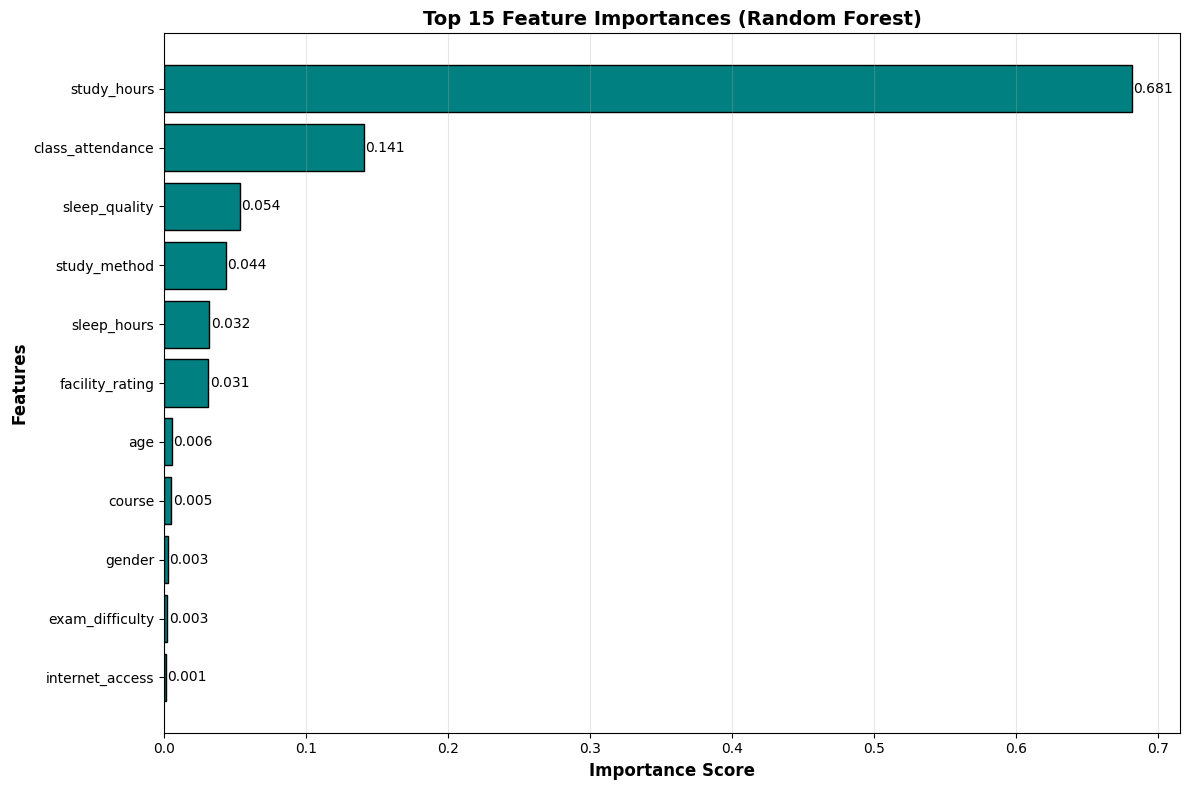

In [9]:
# ===== CELL 9: Feature Importance Visualization =====
plt.figure(figsize=(12, 8))
top_features = feature_importance.head(15)
plt.barh(range(len(top_features)), top_features['importance'].values, color='teal', edgecolor='black')
plt.yticks(range(len(top_features)), top_features['feature'].values)
plt.xlabel('Importance Score', fontsize=12, fontweight='bold')
plt.ylabel('Features', fontsize=12, fontweight='bold')
plt.title('Top 15 Feature Importances (Random Forest)', fontsize=14, fontweight='bold')
plt.gca().invert_yaxis()
plt.grid(axis='x', alpha=0.3)

# Add percentage labels
for i, v in enumerate(top_features['importance'].values):
    plt.text(v + 0.001, i, f'{v:.3f}', va='center', fontsize=10)

plt.tight_layout()
plt.show()

In [10]:
# ===== CELL 10: CatBoost (BEST PERFORMANCE) =====
print("\n🐱 TRAINING CATBOOST...")

# Specify categorical feature indices
cat_feature_indices = [X_encoded.columns.get_loc(col) for col in categorical_cols]

cb = CatBoostRegressor(
    iterations=1000,
    learning_rate=0.05,
    depth=8,
    loss_function='RMSE',
    cat_features=cat_feature_indices,  # Use indices
    early_stopping_rounds=50,
    random_seed=42,
    verbose=100  # Show progress every 100 iterations
)

cb.fit(X_encoded, y, eval_set=(X_encoded, y), verbose=100)
cb_preds = cb.predict(X_test_encoded)

print(f"\n✅ CatBoost training complete")


🐱 TRAINING CATBOOST...
0:	learn: 18.2698038	test: 18.2697975	best: 18.2697975 (0)	total: 981ms	remaining: 16m 19s
100:	learn: 8.8515270	test: 8.8498973	best: 8.8498973 (100)	total: 1m 3s	remaining: 9m 25s
200:	learn: 8.8233038	test: 8.8231691	best: 8.8231691 (200)	total: 1m 59s	remaining: 7m 56s
300:	learn: 8.8044430	test: 8.8054290	best: 8.8054290 (300)	total: 3m 2s	remaining: 7m 4s
400:	learn: 8.7863427	test: 8.7877457	best: 8.7877457 (400)	total: 4m 11s	remaining: 6m 16s
500:	learn: 8.7715680	test: 8.7735888	best: 8.7735888 (500)	total: 5m 19s	remaining: 5m 18s
600:	learn: 8.7595833	test: 8.7621318	best: 8.7621318 (600)	total: 6m 25s	remaining: 4m 16s
700:	learn: 8.7478874	test: 8.7513714	best: 8.7513714 (700)	total: 7m 33s	remaining: 3m 13s
800:	learn: 8.7372264	test: 8.7414482	best: 8.7414482 (800)	total: 8m 39s	remaining: 2m 9s
900:	learn: 8.7266772	test: 8.7317742	best: 8.7317742 (900)	total: 9m 48s	remaining: 1m 4s
999:	learn: 8.7168075	test: 8.7226517	best: 8.7226517 (999)	to

In [11]:
# ===== CELL 11: CatBoost Cross-Validation =====
print("\n📊 CatBoost 5-Fold Cross-Validation...")

kf = KFold(n_splits=5, shuffle=True, random_state=42)
oof_cb = np.zeros(len(X_encoded))
cb_fold_scores = []

for fold, (train_idx, val_idx) in enumerate(kf.split(X_encoded), 1):
    print(f"\nFold {fold}/5")
    
    X_tr, X_val = X_encoded.iloc[train_idx], X_encoded.iloc[val_idx]
    y_tr, y_val = y.iloc[train_idx], y.iloc[val_idx]
    
    cb_fold = CatBoostRegressor(
        iterations=1000,
        learning_rate=0.05,
        depth=8,
        cat_features=cat_feature_indices,
        early_stopping_rounds=50,
        random_seed=42,
        verbose=0
    )
    
    cb_fold.fit(X_tr, y_tr, eval_set=(X_val, y_val), verbose=0)
    oof_cb[val_idx] = cb_fold.predict(X_val)
    
    fold_rmse = mean_squared_error(y_val, oof_cb[val_idx]) ** 0.5
    cb_fold_scores.append(fold_rmse)
    print(f"Fold {fold} RMSE: {fold_rmse:.4f}")

cb_cv_rmse = np.mean(cb_fold_scores)
print(f"\n🎯 CatBoost CV RMSE: {cb_cv_rmse:.4f} (±{np.std(cb_fold_scores):.4f})")


📊 CatBoost 5-Fold Cross-Validation...

Fold 1/5
Fold 1 RMSE: 8.7647

Fold 2/5
Fold 2 RMSE: 8.7712

Fold 3/5
Fold 3 RMSE: 8.7610

Fold 4/5
Fold 4 RMSE: 8.7759

Fold 5/5
Fold 5 RMSE: 8.7962

🎯 CatBoost CV RMSE: 8.7738 (±0.0123)


In [12]:
# ===== CELL 12: Neural Network (DEEP LEARNING) =====
print("\n🧠 TRAINING NEURAL NETWORK...")

# Scale features for Neural Network
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_encoded)
X_test_scaled = scaler.transform(X_test_encoded)

mlp = MLPRegressor(
    hidden_layer_sizes=(128, 64),  # Two hidden layers
    activation='relu',              # ReLU activation
    solver='adam',                  # Adam optimizer
    alpha=0.0001,                   # L2 regularization
    max_iter=300,
    random_state=42,
    verbose=True,
    early_stopping=True,
    validation_fraction=0.1
)

mlp.fit(X_scaled, y)
mlp_preds = mlp.predict(X_test_scaled)

# Cross-validation
mlp_cv_scores = cross_val_score(mlp, X_scaled, y, 
                                 cv=5, 
                                 scoring='neg_root_mean_squared_error',
                                 n_jobs=-1)
mlp_rmse = -mlp_cv_scores.mean()

print(f"\nNeural Network CV RMSE: {mlp_rmse:.4f} (±{mlp_cv_scores.std():.4f})")


🧠 TRAINING NEURAL NETWORK...
Iteration 1, loss = 91.43461728
Validation score: 0.766222
Iteration 2, loss = 41.35663447
Validation score: 0.771723
Iteration 3, loss = 40.41060109
Validation score: 0.776338
Iteration 4, loss = 40.05782038
Validation score: 0.776947
Iteration 5, loss = 39.91962123
Validation score: 0.777206
Iteration 6, loss = 39.87584808
Validation score: 0.777963
Iteration 7, loss = 39.78477459
Validation score: 0.778565
Iteration 8, loss = 39.74656767
Validation score: 0.778415
Iteration 9, loss = 39.73641717
Validation score: 0.777989
Iteration 10, loss = 39.71724360
Validation score: 0.777239
Iteration 11, loss = 39.68190543
Validation score: 0.778233
Iteration 12, loss = 39.68710286
Validation score: 0.778645
Iteration 13, loss = 39.67664661
Validation score: 0.778533
Iteration 14, loss = 39.66152681
Validation score: 0.776859
Iteration 15, loss = 39.64468152
Validation score: 0.776802
Iteration 16, loss = 39.62935491
Validation score: 0.774502
Iteration 17, loss 

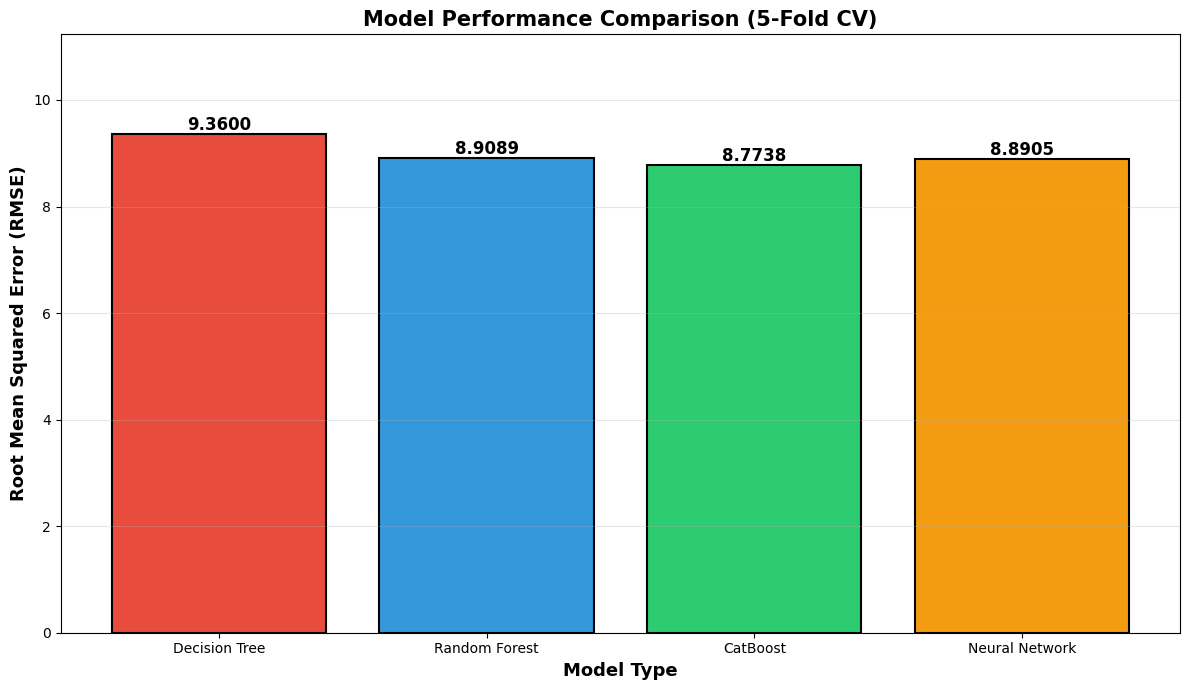


📊 Model Performance Summary:
Decision Tree       : 9.3600 RMSE
Random Forest       : 8.9089 RMSE
CatBoost            : 8.7738 RMSE
Neural Network      : 8.8905 RMSE


In [13]:
# ===== CELL 13: Model Comparison Visualization =====
models = ['Decision Tree', 'Random Forest', 'CatBoost', 'Neural Network']
rmse_scores = [dt_rmse, rf_rmse, cb_cv_rmse, mlp_rmse]
colors = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12']

plt.figure(figsize=(12, 7))
bars = plt.bar(models, rmse_scores, color=colors, edgecolor='black', linewidth=1.5)

# Add value labels on bars
for bar, score in zip(bars, rmse_scores):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{score:.4f}', ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.xlabel('Model Type', fontsize=13, fontweight='bold')
plt.ylabel('Root Mean Squared Error (RMSE)', fontsize=13, fontweight='bold')
plt.title('Model Performance Comparison (5-Fold CV)', fontsize=15, fontweight='bold')
plt.ylim(0, max(rmse_scores) * 1.2)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

print("\n📊 Model Performance Summary:")
for model, score in zip(models, rmse_scores):
    print(f"{model:20s}: {score:.4f} RMSE")

In [14]:
# ===== CELL 14: Weighted Ensemble (FINAL MODEL) =====
print("\n🏆 CREATING WEIGHTED ENSEMBLE...")

# Calculate weights based on inverse RMSE
weights = 1 / np.array(rmse_scores[1:])  # Exclude Decision Tree
weights = weights / weights.sum()

print(f"Model Weights:")
print(f"  Random Forest: {weights[0]:.3f}")
print(f"  CatBoost:      {weights[1]:.3f}")
print(f"  Neural Net:    {weights[2]:.3f}")

# Weighted average of predictions
final_preds = (
    weights[0] * rf_preds +
    weights[1] * cb_preds +
    weights[2] * mlp_preds
)

print(f"\n✅ Ensemble predictions generated")
print(f"Prediction range: [{final_preds.min():.2f}, {final_preds.max():.2f}]")
print(f"Mean prediction: {final_preds.mean():.2f}")


🏆 CREATING WEIGHTED ENSEMBLE...
Model Weights:
  Random Forest: 0.331
  CatBoost:      0.337
  Neural Net:    0.332

✅ Ensemble predictions generated
Prediction range: [17.98, 101.63]
Mean prediction: 62.52


In [16]:
# ===== CELL 15: Create Submission File =====
submission = pd.DataFrame({
    "id": test["id"],
    "exam_score": final_preds
})

submission.to_csv("submission.csv", index=False)

print("\n💾 Submission file created: submission.csv")
print(f"Submission shape: {submission.shape}")
print(f"\nFirst 5 predictions:")
print(submission.head())

print("\n" + "="*60)
print("🎉 ALL DONE! Ready for Kaggle submission!")
print("="*60)


💾 Submission file created: submission.csv
Submission shape: (270000, 2)

First 5 predictions:
       id  exam_score
0  630000   72.021174
1  630001   70.226389
2  630002   86.251627
3  630003   53.839726
4  630004   47.386293

🎉 ALL DONE! Ready for Kaggle submission!


In [17]:
# ===== CELL 16: Save Models for Deployment =====
import pickle
import joblib

print("\n💾 SAVING MODELS FOR DEPLOYMENT...")

# Save the best model (CatBoost)
cb.save_model('catboost_model.cbm')
print("✅ CatBoost model saved: catboost_model.cbm")

# Save Random Forest
joblib.dump(rf, 'random_forest_model.pkl')
print("✅ Random Forest saved: random_forest_model.pkl")

# Save Neural Network + Scaler
joblib.dump(mlp, 'neural_network_model.pkl')
joblib.dump(scaler, 'scaler.pkl')
print("✅ Neural Network + Scaler saved")

# Save Label Encoders
joblib.dump(label_encoders, 'label_encoders.pkl')
print("✅ Label Encoders saved")

# Save feature names for reference
feature_info = {
    'categorical_cols': categorical_cols,
    'numerical_cols': numerical_cols,
    'cat_feature_indices': cat_feature_indices,
    'feature_names': list(X_encoded.columns)
}
joblib.dump(feature_info, 'feature_info.pkl')
print("✅ Feature info saved")

# Save ensemble weights
ensemble_weights = {
    'rf_weight': weights[0],
    'cb_weight': weights[1],
    'mlp_weight': weights[2]
}
joblib.dump(ensemble_weights, 'ensemble_weights.pkl')
print("✅ Ensemble weights saved")

print("\n🎉 All models and configurations saved!")
print("\nFiles to download:")
print("  - catboost_model.cbm")
print("  - random_forest_model.pkl")
print("  - neural_network_model.pkl")
print("  - scaler.pkl")
print("  - label_encoders.pkl")
print("  - feature_info.pkl")
print("  - ensemble_weights.pkl")


💾 SAVING MODELS FOR DEPLOYMENT...
✅ CatBoost model saved: catboost_model.cbm
✅ Random Forest saved: random_forest_model.pkl
✅ Neural Network + Scaler saved
✅ Label Encoders saved
✅ Feature info saved
✅ Ensemble weights saved

🎉 All models and configurations saved!

Files to download:
  - catboost_model.cbm
  - random_forest_model.pkl
  - neural_network_model.pkl
  - scaler.pkl
  - label_encoders.pkl
  - feature_info.pkl
  - ensemble_weights.pkl
